In [23]:
import geopandas as gpd
import pandas as pd
import h3pandas

import matplotlib.pyplot as plt

from tobler.area_weighted import area_interpolate
from libpysal.weights import Queen, lag_spatial
from esda.moran import Moran
import numpy as np

plt.rcParams['font.family'] = 'Times New Roman'

In [2]:
h3Res = [7, 8, 9, 10, 11]
sp = gpd.read_file("/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/sp.geojson")
poligono_sp = sp.iloc[0].geometry
years = ["2010", "2022"]

In [3]:
morans = {}

for year in years:

    morans[year] = []

    print('starting ', year)

    _grade = gpd.read_file(f"/Users/camillaperotto/Documents/pde-sp/01_AccessPipeline/data/grade_estatistica/{year}.gpkg")
    grade = _grade[_grade.intersects(poligono_sp)]
    if "DOM_OCU" in grade.columns: grade = grade.rename(columns={"DOM_OCU": 'TOTAL_DOM'})
    grade = grade.loc[grade.TOTAL_DOM>0]
    #print(grade.head(3))
    #print(grade.crs)

    w_base = Queen.from_dataframe(grade)
    w_base.transform = 'r'
    moran_base = Moran(grade["TOTAL_DOM"], w_base)
    morans[year].append({"i": moran_base.I, 'res': f'Real'})
    print({"i": moran_base.I, 'res': f'Real'})

    for res in h3Res:

        hexs = sp.h3.polyfill(res).iloc[0]["h3_polyfill"]
        hexs = pd.DataFrame(index=hexs).h3.h3_to_geo_boundary()
        
        if grade.crs != hexs.crs:
            hexs = hexs.to_crs(grade.crs)

        # Realiza interpolação areal da variável 'domicilios' de grade para aop
        aop_interpolado = area_interpolate(
            source_df=grade,
            target_df=hexs,
            extensive_variables=["TOTAL_DOM"],  # variável a ser interpolada
            allocate_total=True
        )

        hexs['N_HOUSING'] = aop_interpolado['TOTAL_DOM'].values
        hexs['N_HOUSING'] = hexs['N_HOUSING'].round(decimals=0)
        hexs = hexs.loc[hexs.N_HOUSING>0]

        w = Queen.from_dataframe(hexs)
        w.transform = 'r'

        moran = Moran(hexs["N_HOUSING"], w)

        #print(f"\n[Moran's I - {year}, resolução {res}]")
        #print(f"I: {moran.I:.4f}")
        #print(f"p-value (permutações): {moran.p_sim:.4f}")
        #print(f"z-score: {moran.z_sim:.4f}")

        # Intervalo de confiança 95%
        i_mc = np.percentile(moran.sim, [2.5, 97.5])
        #print(f"IC 95% (simulações): {i_mc[0]:.4f} a {i_mc[1]:.4f}")
        #print(f"I está fora do intervalo nulo? {'Sim' if moran.I < i_mc[0] or moran.I > i_mc[1] else 'Não'}")

        #morans[year].append({"i": moran.I, "_low": i_mc[0], "_high": i_mc[1], 'res': f'H3 {res}'})
        morans[year].append({
            "grid": res,
            "I": moran.I,
            "se": moran.seI_sim,  # erro padrão da simulação
            "IC_low": moran.EI_sim - 1.96 * moran.seI_sim,
            "IC_high": moran.EI_sim + 1.96 * moran.seI_sim
        })

        
        print("*****")
        #aop[["h3_09", "N_HOUSING"]].to_csv(f"../data/address/origins__{year}.csv", sep=';', index=False)


starting  2010


/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:16: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w_base = Queen.from_dataframe(grade)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights.py:224: UserWarning: The weights matrix is not fully connected: 
 There are 66 disconnected components.
 There are 34 islands with ids: 172, 208, 209, 635, 636, 1151, 1583, 1638, 2107, 2667, 2831, 2999, 3458, 3846, 3915, 3916, 4534, 8949, 10670, 11392, 11400, 12861, 15531, 15537, 16051, 16586, 16954, 17834, 20083, 21489, 22284, 23458, 23476, 23485.
  warnings.warn(message)


('WARNING: ', 172, ' is an island (no neighbors)')
('WARNING: ', 208, ' is an island (no neighbors)')
('WARNING: ', 209, ' is an island (no neighbors)')
('WARNING: ', 635, ' is an island (no neighbors)')
('WARNING: ', 636, ' is an island (no neighbors)')
('WARNING: ', 1151, ' is an island (no neighbors)')
('WARNING: ', 1583, ' is an island (no neighbors)')
('WARNING: ', 1638, ' is an island (no neighbors)')
('WARNING: ', 2107, ' is an island (no neighbors)')
('WARNING: ', 2667, ' is an island (no neighbors)')
('WARNING: ', 2831, ' is an island (no neighbors)')
('WARNING: ', 2999, ' is an island (no neighbors)')
('WARNING: ', 3458, ' is an island (no neighbors)')
('WARNING: ', 3846, ' is an island (no neighbors)')
('WARNING: ', 3915, ' is an island (no neighbors)')
('WARNING: ', 3916, ' is an island (no neighbors)')
('WARNING: ', 4534, ' is an island (no neighbors)')
('WARNING: ', 8949, ' is an island (no neighbors)')
('WARNING: ', 10670, ' is an island (no neighbors)')
('WARNING: ', 11

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aop_interpolado = area_interpolate(
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/tobler/area_weighted/area_interpolate.py:325: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  den = source_df.area.values
/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:42: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(hexs)


*****


/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aop_interpolado = area_interpolate(
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/tobler/area_weighted/area_interpolate.py:325: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  den = source_df.area.values
/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:42: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(hexs)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights

... (15 outputs left out)

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aop_interpolado = area_interpolate(
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/tobler/area_weighted/area_interpolate.py:325: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  den = source_df.area.values
/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:42: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(hexs)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights

('WARNING: ', 151, ' is an island (no neighbors)')
('WARNING: ', 250, ' is an island (no neighbors)')
('WARNING: ', 1415, ' is an island (no neighbors)')
('WARNING: ', 2129, ' is an island (no neighbors)')
('WARNING: ', 5470, ' is an island (no neighbors)')
('WARNING: ', 5493, ' is an island (no neighbors)')
('WARNING: ', 5578, ' is an island (no neighbors)')
('WARNING: ', 7992, ' is an island (no neighbors)')
('WARNING: ', 14347, ' is an island (no neighbors)')
('WARNING: ', 14910, ' is an island (no neighbors)')
('WARNING: ', 16203, ' is an island (no neighbors)')
('WARNING: ', 21254, ' is an island (no neighbors)')
('WARNING: ', 27212, ' is an island (no neighbors)')
('WARNING: ', 27687, ' is an island (no neighbors)')
('WARNING: ', 37019, ' is an island (no neighbors)')
('WARNING: ', 38492, ' is an island (no neighbors)')
('WARNING: ', 39000, ' is an island (no neighbors)')
('WARNING: ', 39781, ' is an island (no neighbors)')
('WARNING: ', 42012, ' is an island (no neighbors)')
('W

/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  aop_interpolado = area_interpolate(
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/tobler/area_weighted/area_interpolate.py:325: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  den = source_df.area.values
/var/folders/73/66hhl4fn15q00wfhkpxpsy680000gq/T/ipykernel_18079/2250487993.py:42: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(hexs)
/Users/camillaperotto/Documents/pde-sp/.venv/lib/python3.9/site-packages/libpysal/weights/weights

('WARNING: ', 23245, ' is an island (no neighbors)')
('WARNING: ', 56890, ' is an island (no neighbors)')
('WARNING: ', 82570, ' is an island (no neighbors)')
('WARNING: ', 85644, ' is an island (no neighbors)')
('WARNING: ', 120725, ' is an island (no neighbors)')
('WARNING: ', 134629, ' is an island (no neighbors)')
('WARNING: ', 149100, ' is an island (no neighbors)')
('WARNING: ', 156269, ' is an island (no neighbors)')
('WARNING: ', 206392, ' is an island (no neighbors)')
('WARNING: ', 291700, ' is an island (no neighbors)')
('WARNING: ', 316552, ' is an island (no neighbors)')
('WARNING: ', 338145, ' is an island (no neighbors)')
('WARNING: ', 341841, ' is an island (no neighbors)')
('WARNING: ', 373778, ' is an island (no neighbors)')
*****


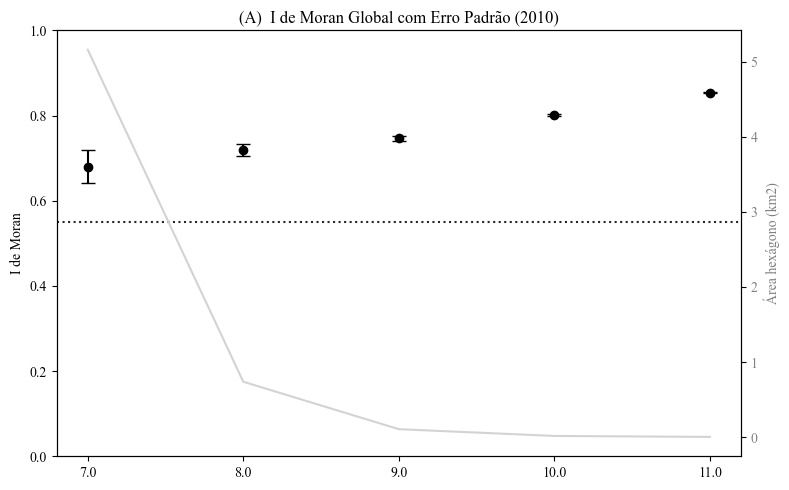

In [38]:
results2010 = pd.DataFrame(morans["2010"])

fig, ax = plt.subplots(figsize=(8, 5))

x = range(len(results2010)-1)
y = results2010["I"].iloc[1:]
yerr = results2010["se"].iloc[1:]

# Pontos com barras de erro
ax.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)

# Estética do gráfico
ax.set_xticks(x)
ax.set_xticklabels(results2010["grid"].iloc[1:])
ax.set_ylabel("I de Moran")
title = "(A)  I de Moran Global com Erro Padrão (2010)"
ax.set_title(title)
ax.set_ylim(0, 1)
#ax.grid(True, axis='y', linestyle='-.', alpha=0.3)
ax.axhline(y=0.5507516774076837, alpha=0.85, linestyle=':', c='black')


ax2 = ax.twinx()
ax2.plot(x, [5.161293, 0.737327598, 0.10533251, 0.015047502, 0.00214964], color='lightgray')
ax2.set_ylabel("Área hexágono (km2)", color='gray')
ax2.tick_params(axis='y', labelcolor='gray')


plt.tight_layout()
plt.savefig(f"{title}.png", dpi=900)
plt.show()

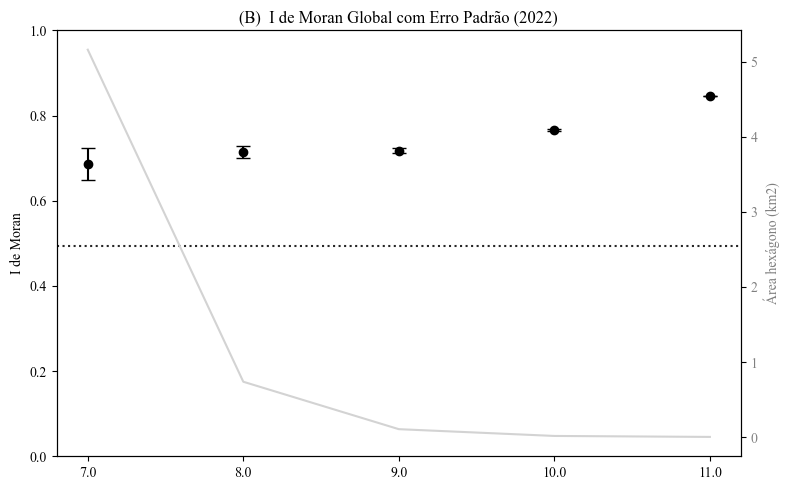

In [39]:
results2022 = pd.DataFrame(morans["2022"])

fig, ax = plt.subplots(figsize=(8, 5))

x = range(len(results2022)-1)
y = results2022["I"].iloc[1:]
yerr = results2022["se"].iloc[1:]

# Pontos com barras de erro
ax.errorbar(x, y, yerr=yerr, fmt='o', color='black', capsize=5)

# Estética do gráfico
ax.set_xticks(x)
ax.set_xticklabels(results2022["grid"][1:])
ax.set_ylabel("I de Moran")
title = "(B)  I de Moran Global com Erro Padrão (2022)"
ax.set_title(title)
ax.set_ylim(0, 1)
#ax.grid(True, axis='y', linestyle='-.', alpha=0.3)
ax.axhline(y=0.49274275574881754, alpha=0.85, linestyle=':', c='black')


ax2 = ax.twinx()
ax2.plot(x, [5.161293, 0.737327598, 0.10533251, 0.015047502, 0.00214964], color='lightgray')
ax2.set_ylabel("Área hexágono (km2)", color='gray')
ax2.tick_params(axis='y', labelcolor='gray')


plt.tight_layout()
plt.savefig(f"{title}.png", dpi=900)
plt.show()

In [13]:
morans["2022"][0], morans["2010"][0]

({'i': 0.49274275574881754, 'res': 'Real'},
 {'i': 0.5507516774076837, 'res': 'Real'})